# CASMI26: a validation set that behaves like the hidden test

**TL;DR**
- The visible `test.parquet` is copied from **`enveda-180`**, a library of mostly drug-like synthetic compounds. The hidden test is natural-product-like. A score on the visible file says little about the leaderboard.
- `enveda-np-examples` is the only training library that is **both natural-product-like and measured on timsTOF**, the test instrument. Its 250 molecules make a natural validation set.
- Removing a molecule's spectra from the reference library **simulates the three novelty classes**, so every idea can be scored per class instead of in one blended number.
- A plain cosine library search scores **MRR 0.94 on class 1 and 0.00 on classes 2/3**, in about 3 minutes. Its public leaderboard score then shows roughly **how much of the hidden test is class 1**.

Everything here is CPU only, needs no external data, and produces a valid submission.

## Setup
All helper code is in the next cell: mass arithmetic, peak cleaning, a greedy cosine, the library index, MRR@25 and the novelty-class split.

In [1]:
import re
from collections import defaultdict

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

PROTON = 1.007276
# m/z = M + shift  (all test adducts are singly charged)
ADDUCT_SHIFT = {
    '[M+H]+': PROTON,
    '[M+NH4]+': 18.033823,
    '[M-H2O+H]+': PROTON - 18.010565,
    '[M-2H2O+H]+': PROTON - 2 * 18.010565,
    '[M+Na]+': 22.989218,
    '[M+K]+': 38.963158,
    '[M-H]-': -PROTON,
    '[M-H2O-H]-': -PROTON - 18.010565,
    '[M+CH2O2-H]-': 44.998201,
    '[M+Cl]-': 34.969402,
}
MONO = {'C': 12.0, 'H': 1.0078250319, 'N': 14.0030740052, 'O': 15.9949146221, 'P': 30.97376151,
        'S': 31.97207069, 'F': 18.99840320, 'Cl': 34.96885271, 'Br': 78.9183376, 'I': 126.904468,
        'Si': 27.9769265327, 'B': 11.0093055, 'Se': 79.9165218, 'Na': 22.98976966, 'K': 38.9637069,
        'As': 74.9215964, 'Fe': 55.9349375, 'Co': 58.933195, 'Cu': 62.9295975, 'Zn': 63.9291422,
        'Mg': 23.9850417, 'Ca': 39.9625912, 'Al': 26.98153853, 'Sn': 119.9021947, 'Hg': 201.970643,
        'Pt': 194.9647911, 'Ge': 73.9211778, 'Li': 7.0160040, 'Mn': 54.9380496, 'Ni': 57.9353429,
        'Gd': 157.9241039, 'Ti': 47.9479463, 'Cr': 51.9405075, 'Ru': 101.9043493, 'Te': 129.9062244,
        'Sb': 120.9038157, 'Bi': 208.9803987, 'Ag': 106.905093, 'Au': 196.966552, 'Pd': 105.903486,
        'Rh': 102.905504, 'W': 183.950933, 'Mo': 97.9054082, 'V': 50.9439595, 'Tl': 204.974427,
        'Pb': 207.976652, 'Ba': 137.905247, 'Sr': 87.9056121, 'Cs': 132.905451, 'Rb': 84.911789,
        'D': 2.0141017778}
TEST_ADDUCTS = list(ADDUCT_SHIFT)


def formula_mass(formula):
    """Monoisotopic neutral mass of a formula like 'C9H6O3'; NaN if it has a charge or unknown element."""
    if not isinstance(formula, str) or not re.fullmatch(r'([A-Z][a-z]?\d*)+', formula):
        return np.nan
    total = 0.0
    for el, n in re.findall(r'([A-Z][a-z]?)(\d*)', formula):
        if el not in MONO:
            return np.nan
        total += MONO[el] * (int(n) if n else 1)
    return total


def neutral_mass(precursor_mz, adduct):
    return precursor_mz - ADDUCT_SHIFT[adduct]


# ---------------------------------------------------------------- spectra

def clean_peaks(mzs, ints, precursor_mz, top_k=60):
    """Keep peaks below the precursor + 2 Da, the top_k most intense, sqrt-scaled and L2-normalised."""
    mz = np.asarray(mzs, dtype=np.float64)
    it = np.asarray(ints, dtype=np.float64)
    keep = (mz < precursor_mz + 2) & (it > 0)
    mz, it = mz[keep], it[keep]
    if len(mz) > top_k:
        idx = np.argpartition(-it, top_k)[:top_k]
        mz, it = mz[idx], it[idx]
    order = np.argsort(mz)
    mz, it = mz[order], np.sqrt(it[order])
    norm = np.linalg.norm(it)
    return mz.astype(np.float32), (it / norm if norm > 0 else it).astype(np.float32)


def cosine(mz_a, it_a, mz_b, it_b, tol=0.02):
    """Greedy cosine: match peak pairs within tol, highest products first, each peak used once."""
    if len(mz_a) == 0 or len(mz_b) == 0:
        return 0.0
    lo = np.searchsorted(mz_b, mz_a - tol)
    hi = np.searchsorted(mz_b, mz_a + tol)
    pairs = [(it_a[i] * it_b[j], i, j) for i in range(len(mz_a)) for j in range(lo[i], hi[i])]
    if not pairs:
        return 0.0
    pairs.sort(reverse=True)
    used_a, used_b, score = set(), set(), 0.0
    for p, i, j in pairs:
        if i not in used_a and j not in used_b:
            used_a.add(i), used_b.add(j)
            score += p
    return float(score)


class Library:
    """Reference spectra stored flat (one peak array + offsets), indexed by neutral structure mass."""

    def __init__(self, meta, mz, it, offsets, struct_mass, struct_smiles):
        self.meta = meta                    # per-spectrum: inchikey14, ionization_mode, ingest_lib
        self.mz, self.it, self.offsets = mz, it, offsets
        self.struct_keys = struct_mass.index.to_numpy()
        self.struct_mass = struct_mass.to_numpy()
        order = np.argsort(self.struct_mass)
        self.struct_keys, self.struct_mass = self.struct_keys[order], self.struct_mass[order]
        self.smiles = struct_smiles
        self.spectra_of = meta.groupby('inchikey14').indices

    @classmethod
    def build(cls, path, keep=None, top_k=60, batch_size=50_000):
        """keep(df) -> boolean mask selecting the library rows (default: all rows)."""
        cols = ['inchikey14', 'normalized_smiles', 'molecular_formula', 'ionization_mode', 'ingest_lib',
                'adduct', 'precursor_mz', 'ms2_mzs', 'ms2_normalized_intensities']
        metas, mzs, its, lens = [], [], [], []
        for batch in pq.ParquetFile(path).iter_batches(batch_size=batch_size, columns=cols):
            df = batch.to_pandas()
            if keep is not None:
                df = df[keep(df)]
            for p_mz, a, b in zip(df.precursor_mz.to_numpy(), df.ms2_mzs, df.ms2_normalized_intensities):
                m, i = clean_peaks(a, b, p_mz, top_k)
                mzs.append(m), its.append(i), lens.append(len(m))
            metas.append(df[['inchikey14', 'normalized_smiles', 'molecular_formula', 'ionization_mode', 'ingest_lib']])
        meta = pd.concat(metas, ignore_index=True)
        offsets = np.zeros(len(lens) + 1, dtype=np.int64)
        offsets[1:] = np.cumsum(lens)
        structs = meta.drop_duplicates('inchikey14').set_index('inchikey14')
        struct_mass = structs.molecular_formula.map(formula_mass).dropna()
        return cls(meta[['inchikey14', 'ionization_mode', 'ingest_lib']].copy(),
                   np.concatenate(mzs), np.concatenate(its), offsets, struct_mass,
                   structs.normalized_smiles.to_dict())

    def peaks(self, k):
        a, b = self.offsets[k], self.offsets[k + 1]
        return self.mz[a:b], self.it[a:b]

    def structures_near(self, mass, ppm=10):
        tol = mass * ppm * 1e-6
        lo, hi = np.searchsorted(self.struct_mass, [mass - tol, mass + tol])
        return self.struct_keys[lo:hi]


# ---------------------------------------------------------------- search

def molecule_mass(spectra):
    """Median neutral mass over a molecule's spectra (robust to one odd precursor)."""
    return float(np.median([neutral_mass(p, a) for p, a in zip(spectra.precursor_mz, spectra.adduct)]))


def rank_molecule(lib, spectra, ppm=10, tol=0.02, top_k=60, n=25):
    """Rank library structures for one molecule.

    Candidates are structures whose formula mass is within ppm of the molecule's neutral mass.
    Each candidate scores the sum, over the query spectra, of its best cosine against any
    reference spectrum of that structure in the same ionisation mode.
    """
    cands = lib.structures_near(molecule_mass(spectra), ppm)
    if len(cands) == 0:
        return [], {}
    queries = [(clean_peaks(a, b, p, top_k), mode) for a, b, p, mode in
               zip(spectra.ms2_mzs, spectra.ms2_normalized_intensities, spectra.precursor_mz,
                   spectra.ionization_mode)]
    modes = lib.meta.ionization_mode.to_numpy()
    scores = {}
    for key in cands:
        total = 0.0
        refs = lib.spectra_of.get(key, [])
        for (q_mz, q_it), mode in queries:
            best = 0.0
            for k in refs:
                if modes[k] == mode:
                    r_mz, r_it = lib.peaks(k)
                    best = max(best, cosine(q_mz, q_it, r_mz, r_it, tol))
            total += best
        scores[key] = total / len(queries)
    ranked = sorted(scores, key=scores.get, reverse=True)[:n]
    return ranked, scores


# ---------------------------------------------------------------- metric + validation

def mrr_at_25(ranked_keys, true_key):
    for r, k in enumerate(ranked_keys[:25], 1):
        if k == true_key:
            return 1.0 / r
    return 0.0


def make_validation(meta, query_lib='enveda-np-examples', n_class1=125, seed=0):
    """Split the timsTOF natural-product molecules into simulated novelty classes.

    class 1 (in public libraries): the molecule's other public spectra stay in the reference library.
    class 2/3 (no public spectra): every spectrum of the structure is removed from the library,
        so only a structure database (PubChem / COCONUT) or a de novo model can still find it.
    Returns the query rows and a mask of training rows allowed in the reference library.
    """
    rng = np.random.default_rng(seed)
    q = meta[(meta.ingest_lib == query_lib) & meta.adduct.isin(TEST_ADDUCTS)]
    keys = np.array(sorted(q.inchikey14.unique()))
    rng.shuffle(keys)
    novelty = pd.Series(2, index=keys)
    novelty.iloc[:n_class1] = 1
    banned = set(novelty.index[novelty == 2])
    library_mask = (meta.ingest_lib != query_lib) & ~meta.inchikey14.isin(banned)
    return q.index.to_numpy(), novelty, library_mask.to_numpy()

In [2]:
import glob, time
from pathlib import Path
import matplotlib.pyplot as plt

found = glob.glob('/kaggle/input/**/train.parquet', recursive=True)
DATA = Path(found[0]).parent if found else Path('../../enveda_data')
TRAIN, TEST = DATA / 'train.parquet', DATA / 'test.parquet'
meta = pd.read_parquet(TRAIN, columns=['inchikey14', 'ingest_lib', 'adduct', 'instrument_type',
                                       'molecular_formula', 'precursor_mz', 'base_peak_intensity'])
test = pd.read_parquet(TEST)
print(f'train: {len(meta):,} spectra, {meta.inchikey14.nunique():,} structures | test: {len(test):,} spectra, '
      f'{test.molecule_id.nunique()} molecules')

train: 2,539,608 spectra, 275,810 structures | test: 1,213 spectra, 400 molecules


## 1. Where do the training spectra come from?
Only two libraries were measured on the test instrument (timsTOF), and they are very different:

In [3]:
lib = meta.groupby('ingest_lib').agg(spectra=('inchikey14', 'size'), structures=('inchikey14', 'nunique'))
lib['timsTOF %'] = (meta.instrument_type.fillna('').str.contains('tims', case=False)
                    .groupby(meta.ingest_lib).mean() * 100).round(0)
public = set(meta.loc[~meta.ingest_lib.str.startswith('enveda'), 'inchikey14'])
lib['also in public libraries %'] = [round(100 * len(set(g) & public) / len(set(g)), 1) if name.startswith('enveda')
                                     else '' for name, g in meta.groupby('ingest_lib').inchikey14]
lib.sort_values('spectra', ascending=False)

,spectra,structures,timsTOF %,also in public libraries %
ingest_lib,,,,
enveda-180,1153785,182941,100.0,1.3
pluskal_ms2,527581,46821,0.0,
riken,347171,15892,0.0,
gnps,220849,45750,0.0,
massbank,101727,9180,0.0,
mona,92416,11681,0.0,
spectraverse,50933,9631,0.0,
msdial,40765,9127,0.0,
drug_plus,2545,2539,0.0,


- **`enveda-180`** holds 1.15M timsTOF spectra, but almost none of its structures (about 1%) appear in any public library. The formulas are full of F and Cl, which points to screening-library compounds, not natural products.
- **`enveda-np-examples`** holds 250 natural products on timsTOF, and **every one** has public spectra elsewhere in the training set.

## 2. The visible test file is from `enveda-180`
Joining the visible test spectra to the training set on precursor m/z, raw base-peak intensity and adduct matches every row:

In [4]:
j = test.merge(meta[['precursor_mz', 'base_peak_intensity', 'adduct', 'ingest_lib']],
               on=['precursor_mz', 'base_peak_intensity', 'adduct'], how='left')
j.ingest_lib.value_counts(dropna=False)

ingest_lib
enveda-180    1228
Name: count, dtype: int64

So any score on the visible file measures how well a method finds **synthetic** compounds **that are in the training set**. The hidden test is natural-product-like and mostly *not* in the training set. That is why "class 1 MRR = 1.000 on test" in some public notebooks doesn't carry over to the leaderboard.

The masses tell the same story. The overview gives the hidden test a median of 348 Da; natural products run heavier:

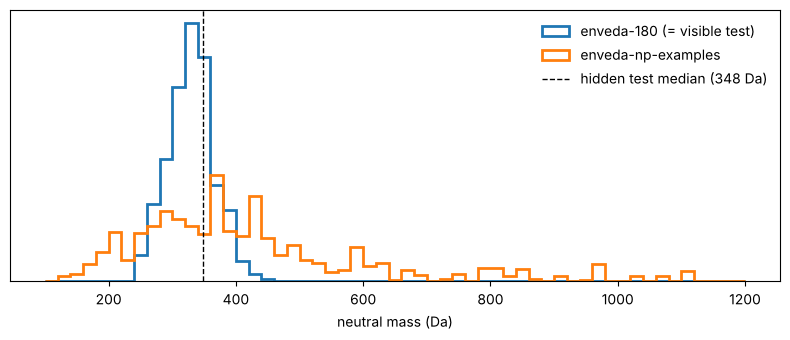

In [5]:
def masses(df):
    return pd.Series([neutral_mass(p, a) for p, a in zip(df.precursor_mz, df.adduct) if a in ADDUCT_SHIFT])

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(100, 1200, 56)
for name, df in [('enveda-180 (= visible test)', meta[meta.ingest_lib == 'enveda-180'].sample(50_000, random_state=0)),
                 ('enveda-np-examples', meta[meta.ingest_lib == 'enveda-np-examples'])]:
    ax.hist(masses(df), bins=bins, density=True, histtype='step', lw=2, label=name)
ax.axvline(348, color='k', ls='--', lw=1, label='hidden test median (348 Da)')
ax.set_xlabel('neutral mass (Da)'); ax.set_yticks([]); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Simulating the novelty classes
The hidden test mixes three classes: **(1)** the structure has public spectra, **(2)** a known structure without public spectra, **(3)** a novel structure. With the 250 `enveda-np-examples` molecules as queries:

- **class 1:** half the molecules keep their *public* spectra in the reference library. Only their own timsTOF spectra are held out.
- **class 2/3:** for the other half, *every* spectrum of the structure is removed. Only a structure database (PubChem, COCONUT) or a de novo model could still find them.

The split is by structure (InChIKey14), the same identity the metric uses, so a held-out molecule can't leak back in under a different stereo form.

In [6]:
q_rows, novelty, _ = make_validation(meta)
banned = set(novelty.index[novelty == 2])
print(f'{len(novelty)} validation molecules: {(novelty == 1).sum()} class 1, {(novelty == 2).sum()} class 2/3, '
      f'{len(q_rows)} query spectra')

250 validation molecules: 125 class 1, 125 class 2/3, 1184 query spectra


## 4. Baseline: cosine library search
For each molecule:
1. Take the neutral mass as the median over its spectra (precursor m/z minus the adduct shift).
2. Use as candidates every library structure whose formula mass is within **10 ppm**.
3. Give each candidate, for each query spectrum, its best cosine against that structure's reference spectra in the same ion mode (0.02 Da tolerance, sqrt intensities, top 60 peaks). Average over the query spectra.

The reference library uses only the ten test adducts. Building it takes about 2–3 minutes.

In [7]:
t = time.time()
val_lib = Library.build(TRAIN, keep=lambda df: (df.ingest_lib != 'enveda-np-examples')
                        & df.adduct.isin(TEST_ADDUCTS) & ~df.inchikey14.isin(banned))
print(f'library: {len(val_lib.meta):,} spectra, {len(val_lib.struct_keys):,} structures, {time.time() - t:.0f}s')

queries = pd.read_parquet(TRAIN, filters=[('ingest_lib', '=', 'enveda-np-examples')])
queries = queries[queries.adduct.isin(TEST_ADDUCTS)]
rows = []
for key, spectra in queries.groupby('inchikey14'):
    ranked, scores = rank_molecule(val_lib, spectra)
    rows.append(dict(key=key, novelty=novelty[key], rr=mrr_at_25(ranked, key), candidates=len(scores),
                     top_score=max(scores.values(), default=0)))
res = pd.DataFrame(rows)
res.groupby('novelty').agg(molecules=('rr', 'size'), MRR=('rr', 'mean'), top1=('rr', lambda r: (r == 1).mean()),
                           median_candidates=('candidates', 'median')).round(3)

library: 2,150,485 spectra, 269,556 structures, 133s


,molecules,MRR,top1,median_candidates
novelty,,,,
1,125,0.939,0.904,14.0
2,125,0.000,0.000,12.0


Class 1 is close to solved by plain cosine search. Classes 2/3 score exactly zero, because the right answer isn't among the candidates at all.

The best cosine score also says which class a molecule is probably in, which is useful for gating other methods:

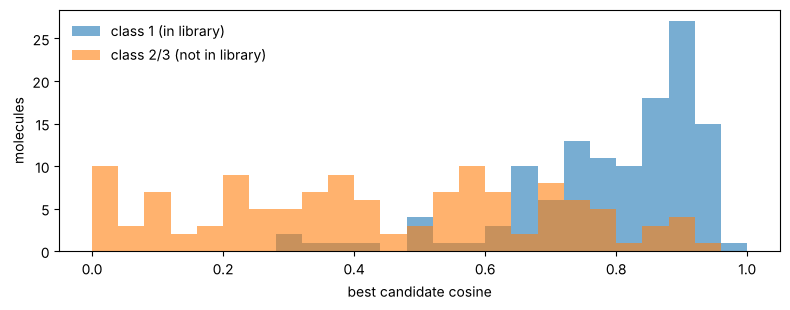

cosine >= 0.5: flags 69% of molecules, 68% of them truly class 1
cosine >= 0.6: flags 60% of molecules, 75% of them truly class 1
cosine >= 0.7: flags 48% of molecules, 81% of them truly class 1


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for c, label in [(1, 'class 1 (in library)'), (2, 'class 2/3 (not in library)')]:
    ax.hist(res.loc[res.novelty == c, 'top_score'], bins=np.linspace(0, 1, 26), alpha=.6, label=label)
ax.set_xlabel('best candidate cosine'); ax.set_ylabel('molecules'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
for th in (0.5, 0.6, 0.7):
    hit = res.top_score >= th
    print(f'cosine >= {th}: flags {hit.mean():.0%} of molecules, {(res.novelty[hit] == 1).mean():.0%} of them truly class 1')

## 5. What this means for the leaderboard
If cosine search reaches MRR ≈ 0.94 on class 1 and 0 elsewhere, its leaderboard score is about `0.94 × (share of class 1)`. Submitting this notebook shows that share for the public test, and so how much of the score is left in classes 2/3.

In [9]:
c1 = res.loc[res.novelty == 1, 'rr'].mean()
for lb in (0.15, 0.20, 0.25, 0.30):
    print(f'public LB {lb:.2f}  ->  about {lb / c1:.0%} of public test molecules are class 1')

public LB 0.15  ->  about 16% of public test molecules are class 1
public LB 0.20  ->  about 21% of public test molecules are class 1
public LB 0.25  ->  about 27% of public test molecules are class 1
public LB 0.30  ->  about 32% of public test molecules are class 1


## 6. Submission
The same search against the *full* training library (all ten test adducts, nothing held out).

In [10]:
del val_lib   # free memory before building the full library
t = time.time()
full_lib = Library.build(TRAIN, keep=lambda df: df.adduct.isin(TEST_ADDUCTS))
print(f'full library: {len(full_lib.meta):,} spectra, {time.time() - t:.0f}s')

sub = []
for mol, spectra in test.groupby('molecule_id', sort=False):
    spectra = spectra[spectra.adduct.isin(TEST_ADDUCTS)]   # the overview promises only these; guard anyway
    ranked = rank_molecule(full_lib, spectra)[0] if len(spectra) else []
    smiles = [full_lib.smiles[k] for k in ranked] or ['C']
    sub.append((mol, ';'.join(smiles)))
sub = pd.DataFrame(sub, columns=['molecule_id', 'smiles'])
sub.to_csv('submission.csv', index=False)
print(sub.shape, 'molecules with no mass-matched candidate:', (sub.smiles == 'C').sum())
sub.head()

full library: 2,176,877 spectra, 136s


(400, 2) molecules with no mass-matched candidate: 0


,molecule_id,smiles
0,m_005e53,CN(Cc1ncccc1C(=O)O)CC1(c2ccc(Br)cc2)CC1;O=C(O)...
1,m_006153,COc1ccc(N2CC(C(=O)Nc3nncn3C3CC3)CC2=O)cc1;COc1...
2,m_00b5aa,COc1ccnc(CN2CCOCC3(CCCC3)C2)c1OC;CC(C)(C)c1cc(...
3,m_01e922,Cc1ccc(C(=O)OCC2CCCCC2)c(=O)[nH]1;COc1ccc(CNC(...
4,m_0259d4,O=C(NCCCn1ccnc1)NCCc1coc(-c2ccccc2)n1;Cc1ccc2[...


## Takeaways
1. **Don't tune on the visible test file.** It is synthetic `enveda-180` data that is already in the training set.
2. **Score ideas per class.** A change that helps class 2/3 can look flat in a blended number while class 1 stays near 0.94.
3. **The headroom is in classes 2/3.** That means structure databases (COCONUT, PubChem) ranked by a spectrum → fingerprint model or in-silico fragmentation. I'll look at those next, using this validation set.

*If this helped, an upvote helps others find it. Questions and corrections are welcome in the comments.*